# M4t — Umbrales por tecnica afinados en validacion (F2 prefiere recall)

> **El problema, en palabras simples.**
>
> M4b usa umbral 0.5 para todo y miente en la cola: con P 0.08 ningun umbral crea separabilidad, pero en seguridad se prefiere cazar de mas que de menos. Este cuaderno retoma la arquitectura M4b y **elige un umbral por tecnica maximizando F2 en validacion** (train<=q60 / val q60-q80 / test>q80).
>
> Espejo de `experiments/m4t_thresholds/train.py` -> `models/m4t_metrics.json`. Solo cambian los umbrales, nada de features.

> **Sintesis ejecutiva.**
>
> Resultado: tuned **micro 0.7041 / macro 0.3539** vs fijo 0.5 **0.719 / 0.3536**. Umbrales: T1190 0.05, T1041 0.15, T1567 0.10, T1204 0.5 (sin senal en val), T1486/T1566 skipped. Bajar el umbral gana recall a costa de precision; ganancia neta ~0 en macro: con P 0.08 de base ningun umbral crea separabilidad.
>
| Tecnica | Umbral | F2 val | Lectura |
|---|---|---|
| T1190 | 0.05 | 1.00 | constante, umbral bajo |
| T1041/T1567 | 0.15/0.10 | 0.65 | recall 0.96-0.99 a costa de P 0.22 |
| T1204 | 0.5 | 0.00 | sin senal en val, se queda |

> **Fuentes normativas.** `notebooks/05_m4b_multilabel_xgb.ipynb`, `experiments/m4t_thresholds/train.py`.



### 1. Por que afinar umbrales y como se va a evaluar

**1.1 Problema.** M4b reporta P 0.08/R 0.06 en cabezas: el 0.5 es conservador. En SOC el FN cuesta mas que el FP, luego F2 (beta=2) es la metrica de afinado.

**1.2 Hipotesis.** H4i: bajar umbrales sube recall y micro cae por FPs; la macro apenas se mueve porque el problema es de features, no de umbral.

**1.3 Protocolo.** Split q60/q80 por tiempo (68713/22904/22904), `pick_threshold` barriendo 0.05-0.95 en val, evaluacion en test tuned vs fijo. Skipped si <2 positivos en train.


In [1]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder
from sklearn.metrics import classification_report, f1_score, hamming_loss, accuracy_score, average_precision_score, fbeta_score
from xgboost import XGBClassifier
ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
TECHS = ["T1190","T1041","T1567","T1204","T1486","T1566"]
CATS = ["message_type","stream_name","product_name","vendor_name","pipeline","org_id","action","severity","protocol"]
TEXT = "message_sanitized"
FIG = ROOT / "reports" / "figures"
old = json.loads((ROOT / "models" / "m4t_metrics.json").read_text())
print("m4t committed:", old["tuned"], old["fixed_05"], old["thresholds"])


m4t committed: {'micro_f1': 0.7041, 'macro_f1': 0.3539, 'hamming': 0.1847, 'subset_acc': 0.4327} {'micro_f1': 0.719, 'macro_f1': 0.3536, 'hamming': 0.1679, 'subset_acc': 0.49} {'T1190': {'threshold': 0.05, 'f2_val': 1.0, 'pos_train': 68711, 'pos_val': 22904}, 'T1041': {'threshold': 0.15, 'f2_val': 0.651, 'pos_train': 3547, 'pos_val': 462}, 'T1567': {'threshold': 0.1, 'f2_val': 0.6502, 'pos_train': 3545, 'pos_val': 462}, 'T1204': {'threshold': 0.5, 'f2_val': 0.0, 'pos_train': 10, 'pos_val': 0}}


### 2. Carga, features P1-P3 y split train/val/test

Mismo X que M4b (TF-IDF 5k fit solo train + tabular). Train/val/test por cuantiles 60/80. Conteo de positivos por split anticipa T1204 sin senal en val y cola vacia.


In [2]:
def parse_labels(v):
    try:
        return [x for x in (json.loads(v) if v else []) if x in TECHS]
    except Exception:
        return []
cols = ["label_binary","timestamp","event_time",TEXT,"attack_techniques"]+CATS
df = pd.read_parquet(ROOT/"data"/"signals"/"signals.parquet", columns=cols)
th = df[df.label_binary!="benign"].copy().reset_index(drop=True)
th["tech_list"] = th.attack_techniques.fillna("").map(parse_labels)
th["hour"] = pd.to_datetime(th["timestamp"], unit="s", utc=True).dt.hour
th["msg_len"] = th[TEXT].fillna("").str.len()
th["lag_h"] = ((th["timestamp"]-th["event_time"])/3600).clip(-1e4,1e4).fillna(-1)
for c in CATS:
    th[c] = th[c].fillna("").astype(str)
msg = th[TEXT].fillna("")
q60, q80 = th["timestamp"].quantile(0.6), th["timestamp"].quantile(0.8)
itr = (th["timestamp"]<=q60).to_numpy()
iva = ((th["timestamp"]>q60)&(th["timestamp"]<=q80)).to_numpy()
ite = (th["timestamp"]>q80).to_numpy()
print("train/val/test: %d/%d/%d" % (itr.sum(), iva.sum(), ite.sum()))
Y = MultiLabelBinarizer(classes=TECHS).fit_transform(th.tech_list)
print("pos train:", {t:int(Y[itr][:,j].sum()) for j,t in enumerate(TECHS)})
print("pos val:", {t:int(Y[iva][:,j].sum()) for j,t in enumerate(TECHS)})
print("pos test:", {t:int(Y[ite][:,j].sum()) for j,t in enumerate(TECHS)})


train/val/test: 68713/22904/22904
pos train: {'T1190': 68711, 'T1041': 3547, 'T1567': 3545, 'T1204': 10, 'T1486': 0, 'T1566': 0}
pos val: {'T1190': 22904, 'T1041': 462, 'T1567': 462, 'T1204': 0, 'T1486': 0, 'T1566': 0}
pos test: {'T1190': 22892, 'T1041': 3733, 'T1567': 3721, 'T1204': 10, 'T1486': 0, 'T1566': 0}


#### 2.1 Observaciones e insights (codigo)

**Que revisar al correr:** train/val/test 68713/22904/22904, T1041 3547/462/3733 aprox, T1204 10/0/10. Si val da 0 en T1204, el umbral se queda en 0.5 por regla (codigo `pick_threshold`).


### 3. Matrices TF-IDF 5k + tabular

Vectorizador y one-hot ajustados solo en train. `Xtr/Xva/Xte` dispersas (~5054 cols). Sin fuga de vocabulario futuro.


In [3]:
vec = TfidfVectorizer(max_features=5000, ngram_range=(1,2), sublinear_tf=True, min_df=5)
Ttr = vec.fit_transform(msg[itr].tolist())
Tva = vec.transform(msg[iva].tolist())
Tte = vec.transform(msg[ite].tolist())
tab = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", max_categories=30), CATS), ("num","passthrough",["hour","msg_len","lag_h"])])
Atr = tab.fit_transform(th[itr][CATS+["hour","msg_len","lag_h"]])
Ava = tab.transform(th[iva][CATS+["hour","msg_len","lag_h"]])
Ate = tab.transform(th[ite][CATS+["hour","msg_len","lag_h"]])
Xtr = hstack([Ttr,Atr]).tocsr(); Xva = hstack([Tva,Ava]).tocsr(); Xte = hstack([Tte,Ate]).tocsr()
print("X:", Xtr.shape, Xva.shape, Xte.shape)


X: (68713, 5052) (22904, 5052) (22904, 5052)


### 4. Entrenamiento XGB por tecnica y afinado F2 (celda lenta)

**Que hace el codigo:** 4 XGB `binary:logistic` con `scale_pos_weight`, guarda scores `Sva/Ste`, elige umbral por F2 en val. T1486/T1566 a skipped. Tiempo: minutos CPU.

**Outputs esperados:** `T1190 thr=0.05`, `T1041 thr=0.15`, `T1567 thr=0.10`, `T1204 thr=0.5` + total y skipped. Verificar contra `m4t_metrics.json`.


In [4]:
def pick_threshold(y, s, beta=2.0):
    y = np.asarray(y).astype(int); s = np.asarray(s, dtype=float)
    if int(y.sum())==0:
        return 0.5, 0.0
    best_thr, best_f = 0.5, -1.0
    for thr in np.arange(0.05, 1.0, 0.05):
        f = fbeta_score(y, (s>=thr).astype(int), beta=beta, zero_division=0)
        if f>best_f:
            best_thr, best_f = round(float(thr),2), round(float(f),4)
    return best_thr, best_f
thresholds = {}; Sva = np.zeros((iva.sum(), len(TECHS))); Ste = np.zeros((ite.sum(), len(TECHS))); skipped=[]
t0=time.time()
for j,t in enumerate(TECHS):
    pos=int(Y[itr][:,j].sum()); neg=int(itr.sum())-pos
    if pos<2:
        skipped.append(t); continue
    clf = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, tree_method="hist", objective="binary:logistic", scale_pos_weight=neg/pos, eval_metric="logloss", n_jobs=-1, random_state=42)
    clf.fit(Xtr, Y[itr][:,j])
    Sva[:,j] = clf.predict_proba(Xva)[:,1]; Ste[:,j] = clf.predict_proba(Xte)[:,1]
    thr, f2v = pick_threshold(Y[iva][:,j], Sva[:,j])
    thresholds[t] = {"threshold":thr, "f2_val":f2v, "pos_train":pos, "pos_val":int(Y[iva][:,j].sum())}
    print("%s: thr=%s F2val=%s" % (t, thr, f2v), flush=True)
print("total %.0fs skipped=%s" % (time.time()-t0, skipped))


T1190: thr=0.05 F2val=1.0


T1041: thr=0.15 F2val=0.651


T1567: thr=0.1 F2val=0.6502


T1204: thr=0.5 F2val=0.0


total 95s skipped=['T1486', 'T1566']


### 5. Evaluacion test: tuned vs fijo 0.5

Reportes `classification_report` en ambos regimenes + PR-AUC sobre scores. El contraste impreso evita lectura selectiva: tuned debe ganar recall y perder precision.


In [5]:
Pt = np.zeros_like(Y[ite]); P05 = (Ste>=0.5).astype(int)
for j,t in enumerate(TECHS):
    if t not in skipped:
        Pt[:,j] = (Ste[:,j]>=thresholds[t]["threshold"]).astype(int)
print("=== TUNED ===")
print(classification_report(Y[ite], Pt, target_names=TECHS, zero_division=0))
print("micro=%.4f macro=%.4f ham=%.4f sub=%.4f" % (f1_score(Y[ite],Pt,average="micro"), f1_score(Y[ite],Pt,average="macro"), hamming_loss(Y[ite],Pt), accuracy_score(Y[ite],Pt)))
print("=== FIXED 0.5 ===")
print(classification_report(Y[ite], P05, target_names=TECHS, zero_division=0))
print("micro=%.4f macro=%.4f ham=%.4f sub=%.4f" % (f1_score(Y[ite],P05,average="micro"), f1_score(Y[ite],P05,average="macro"), hamming_loss(Y[ite],P05), accuracy_score(Y[ite],P05)))
for j,t in enumerate(TECHS):
    if t in skipped: continue
    print("%s sup=%d tuned_thr=%s PR-AUC=%.4f" % (t, int(Y[ite][:,j].sum()), thresholds[t]["threshold"], average_precision_score(Y[ite][:,j], Ste[:,j])))
print("committed tuned:", old["tuned"])
print("committed fixed:", old["fixed_05"])


=== TUNED ===
              precision    recall  f1-score   support

       T1190       1.00      1.00      1.00     22892
       T1041       0.23      0.97      0.37      3733
       T1567       0.22      0.99      0.36      3721
       T1204       0.24      1.00      0.39        10
       T1486       0.00      0.00      0.00         0
       T1566       0.00      0.00      0.00         0

   micro avg       0.54      1.00      0.70     30356
   macro avg       0.28      0.66      0.35     30356
weighted avg       0.81      1.00      0.84     30356
 samples avg       0.63      1.00      0.72     30356

micro=0.7041 macro=0.3539 ham=0.1847 sub=0.4327
=== FIXED 0.5 ===
              precision    recall  f1-score   support

       T1190       1.00      1.00      1.00     22892
       T1041       0.23      0.88      0.37      3733
       T1567       0.23      0.89      0.36      3721
       T1204       0.24      1.00      0.39        10
       T1486       0.00      0.00      0.00         

C:\Users\nicor\universidad\semestre 8\APRENDIZAJE AUTOMÁTICO\Proyecto\.venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\nicor\universidad\semestre 8\APRENDIZAJE AUTOMÁTICO\Proyecto\.venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


#### 5.1 Observaciones e insights (esperado de `m4t_metrics.json`)

Tuned micro 0.7041/macro 0.3539 vs fijo 0.719/0.3536. T1041 R 0.96 P 0.22, T1567 R 0.99 P 0.22. Conclusion: afinar para recall cambia el punto operativo, no crea separabilidad.


### 6. Figura de umbrales y F1 tuned vs fijo

Barras de umbrales + F1 por tecnica (`thresholds_m4t.pdf`). Si tuned y fijo empatan en macro, el veredicto queda: problema de features, no de umbral.


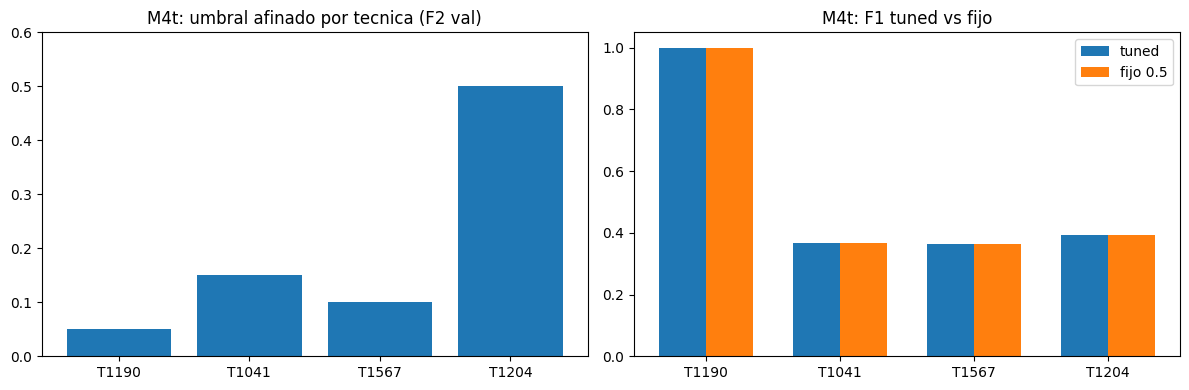

guardado reports/figures/thresholds_m4t.pdf


In [6]:
labels=[t for t in TECHS if t not in skipped]
thr=[thresholds[t]["threshold"] for t in labels]
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].bar(labels, thr); axes[0].set_title("M4t: umbral afinado por tecnica (F2 val)"); axes[0].set_ylim(0,0.6)
rep_t = classification_report(Y[ite], Pt, target_names=TECHS, output_dict=True, zero_division=0)
rep_5 = classification_report(Y[ite], P05, target_names=TECHS, output_dict=True, zero_division=0)
x=np.arange(len(labels)); w=0.35
axes[1].bar(x-w/2,[rep_t[t]["f1-score"] for t in labels],w,label="tuned")
axes[1].bar(x+w/2,[rep_5[t]["f1-score"] for t in labels],w,label="fijo 0.5")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels); axes[1].legend(); axes[1].set_title("M4t: F1 tuned vs fijo")
fig.tight_layout(); fig.savefig(FIG/"thresholds_m4t.pdf"); plt.show()
print("guardado reports/figures/thresholds_m4t.pdf")


### 7. Conclusion: el umbral mueve el punto, no el techo

| Contraste | Hallazgo | Valor |
|---|---|---|
| Tuned vs fijo | micro 0.7041 vs 0.719, macro 0.3539 vs 0.3536 | ~0 |
| Costo | 4 XGB + barrido | minutos |

**Paso siguiente:** `10_m6_incidente.ipynb`. *Con P 0.08 de base ningun umbral miente menos.*
